In [1]:
import numpy as np
from skophys.datasets import ARProcess, ARProcessMovie
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
X = ARProcess(
    n_timepoints=1_000,
    n_components=3,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.1,
    n_pixels_per_component=2,
    n_background_pixels=4,
)

In [3]:
X

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='800.0px', css_width='1000.0px')
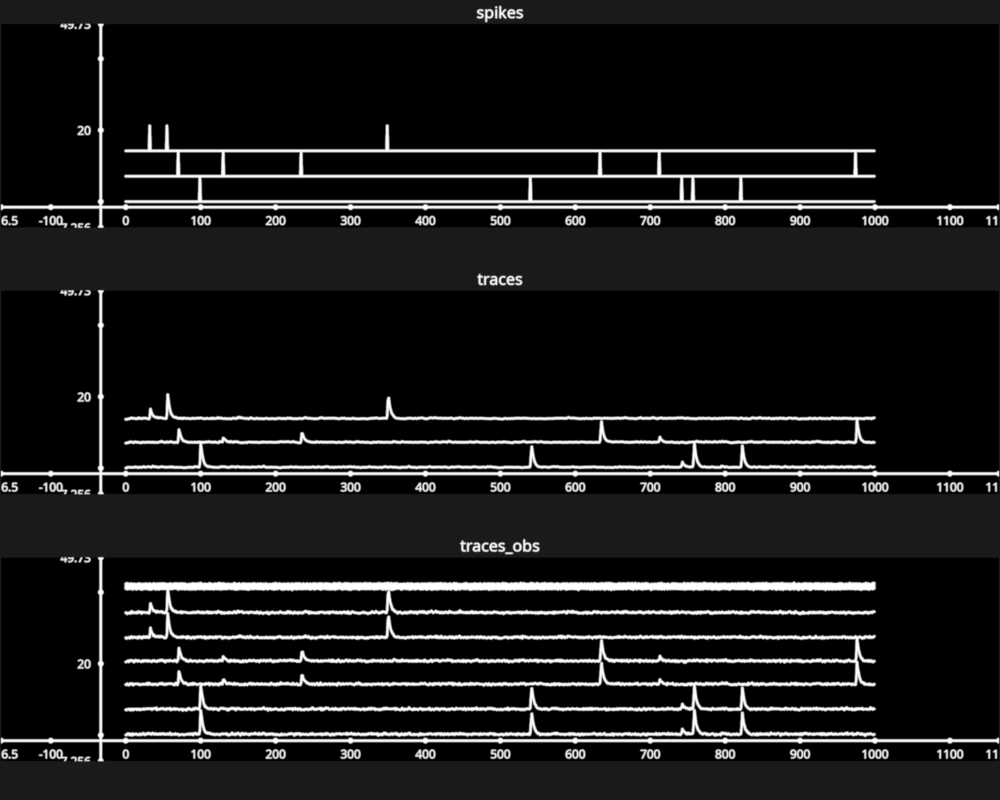

In [4]:
fig = fpl.Figure(shape=(3, 1), names=["spikes", "traces", "traces_obs"], size=(1000, 800), controller_ids="sync")

fig["spikes"].add_line_stack(X.spikes.astype(float) * 7, separation=0.1)
fig["traces"].add_line_stack(X.traces, separation=0.1)
fig["traces_obs"].add_line_stack(X.traces_obs, separation=0.1)

fig.show(maintain_aspect=False)

In [5]:
X.traces

array([[0.01      , 0.01      , 0.18669218, ..., 0.21554558, 0.28343465,
        0.3122658 ],
       [0.01      , 0.01      , 0.08354891, ..., 0.23944197, 0.17875191,
        0.19704493],
       [0.01      , 0.01      , 0.05110458, ..., 0.2779425 , 0.37725439,
        0.42818953]])

In [6]:
X.traces.shape

(3, 1000)

In [7]:
X.traces_obs.shape

(10, 1000)

In [8]:
X.labels

array([ 1,  1,  2,  2,  3,  3, -1, -1, -1, -1])

In [9]:
locs = np.array([
    [0, 0],
    [3, 0]
])

In [10]:
X = ARProcessMovie(
    n_timepoints=5_000,
    n_components=2,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.1,
    movie_dims=(10, 15),
    component_locs=locs,
)

In [11]:
X.movie.shape

(5000, 10, 15)

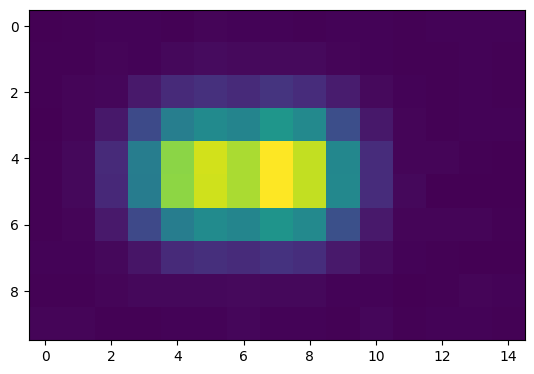

In [12]:
plt.imshow(X.movie.mean(axis=0))

In [13]:
X.traces

array([[0.01      , 0.01      , 0.0795542 , ..., 0.26282266, 0.19372053,
        0.29806354],
       [0.01      , 0.01      , 0.08322761, ..., 0.29572551, 0.29185854,
        0.25429071]])

In [14]:
from ipywidgets import HBox, VBox

In [15]:
iw = fpl.ImageWidget(X.movie, cmap="viridis", figure_kwargs={"size": (500, 500)})

fig_traces = fpl.Figure(size=(900, 500))

traces_lines = fig_traces[0, 0].add_line_collection(X.traces, colors=["b", "r"])

selector = traces_lines[0].add_linear_selector()

def update_time_index(ev: dict | fpl.GraphicFeatureEvent):
    if isinstance(ev, dict):
        index = ev["t"]
    else:
        index = ev.get_selected_index()

    selector.selection = index
    iw.current_index = {"t": index}

selector.add_event_handler(update_time_index, "selection")
iw.add_event_handler(update_time_index)

HBox([iw.show(), fig_traces.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()